# Phase 5: Walk-Forward Backtesting (จำลองการลงทุนจริงรายเดือน 7 ปี)

### คอนเซปต์ใหญ่ของโปรเจกต์นี้คืออะไร?
เรากำลัง **"จำลองการเป็นผู้จัดการกองทุนย้อนอดีตไป 7 ปี (2018–2024)"**:
1. **31 ธ.ค. 2017**: ผู้จัดการกองทุนนั่งดูข้อมูลสถิติหุ้นย้อนหลัง 3 ปี (2015–2017) เพื่อวิเคราะห์ Covariance แล้วตัดสินใจหาน้ำหนักหุ้นที่ดีที่สุด
2. **ม.ค. 2018**: ตลาดเปิด นำเงินไปซื้อหุ้นตามน้ำหนักนั้น ถือครองตลอดเดือน ม.ค. แล้วดูว่าผลตอบแทนจริงแต่ละวันเป็นเท่าไหร่
3. **31 ม.ค. 2018**: สิ้นเดือน เลื่อนหน้าต่างข้อมูลมาเป็น (ก.พ. 2015 – ม.ค. 2018) ปรับพอร์ตใหม่สำหรับเดือน ก.พ. 2018
4. ทำซ้ำแบบนี้ทุกๆ สิ้นเดือนจนครบ **84 เดือน (7 ปีเต็ม)** โดยไม่มีการใช้ข้อมูลล่วงหน้า (No Look-ahead Bias) และคิดค่าคอมมิชชั่น 0.15% ทุกครั้งที่ปรับพอร์ต

## ตอนที่ 1: เตรียมข้อมูลและสร้างปฏิทิน Rebalance

### เซลล์ 1.1: โหลดราคาและแยก Benchmark ออกมา
- `load_price_matrix()`: ดึงตารางราคา Adjusted Close ของหุ้นทั้งหมด 17 ตัว
- `prices["TDEX.BK"]`: ดึงราคาของ TDEX (SET50 ETF) แยกออกมาเป็น Benchmark วัดผล
- `prices.drop(columns=["TDEX.BK"])": เหลือเฉพาะหุ้น 16 ตัวที่จะนำมาจัดพอร์ตแข่งขัน

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data import load_price_matrix
from src.portfolio import (
    get_equal_weights,
    get_inverse_vol_weights,
    get_min_variance_weights,
    get_max_sharpe_weights
)
from src.risk import (
    calculate_annualized_return,
    calculate_annualized_volatility,
    calculate_sharpe_ratio,
    calculate_drawdowns,
    calculate_max_drawdown
)

# โหลดราคาปิดปรับปรุง
prices = load_price_matrix()
bench_prices = prices["TDEX.BK"]
stock_prices = prices.drop(columns=["TDEX.BK"])

print(f"จำนวนหุ้นที่จะจัดพอร์ต: {stock_prices.shape[1]} ตัว")
print(f"ชื่อหุ้น: {list(stock_prices.columns)}")
print(f"Benchmark อ้างอิง: TDEX.BK")
prices.head(2)

จำนวนหุ้นที่จะจัดพอร์ต: 16 ตัว
ชื่อหุ้น: ['ADVANC.BK', 'AOT.BK', 'BBL.BK', 'BDMS.BK', 'BH.BK', 'BJC.BK', 'CPALL.BK', 'CPN.BK', 'DELTA.BK', 'KBANK.BK', 'KTB.BK', 'MINT.BK', 'PTT.BK', 'PTTEP.BK', 'SCC.BK', 'TTB.BK']
Benchmark อ้างอิง: TDEX.BK


ticker,ADVANC.BK,AOT.BK,BBL.BK,BDMS.BK,BH.BK,BJC.BK,CPALL.BK,CPN.BK,DELTA.BK,KBANK.BK,KTB.BK,MINT.BK,PTT.BK,PTTEP.BK,SCC.BK,TDEX.BK,TTB.BK
date,,,,,,,,,,,,,,,,,
2015-01-05,141.822464,24.233814,117.724190,13.616664,105.018890,29.08292,34.182598,35.039536,5.396035,142.203079,12.433333,24.699152,17.544947,59.177643,303.784302,6.057407,1.556339
2015-01-06,140.683350,24.145048,117.414436,13.465370,105.777153,28.55015,33.981529,35.039536,5.239628,138.324875,12.039516,23.726740,17.990532,59.177643,298.383606,6.039342,1.534263


### เซลล์ 1.2: แปลงราคาเป็น Daily Return และสร้างปฏิทินสิ้นเดือน
- `pct_change().dropna()`: คำนวณผลตอบแทนรายวัน $R_t = \frac{P_t - P_{t-1}}{P_{t-1}}$
- `resample("ME").last().index`: ดึงวันทำการสุดท้ายของทุกสิ้นเดือน (Month-Ends) ตลอด 10 ปี (ได้ทั้งหมด 120 เดือน)
- `lookback_months = 36`: หน้าต่างดูข้อมูลย้อนหลัง 36 เดือน (3 ปี)
- `test_months = month_ends[36:]`: ช่วงเวลาทดสอบจริง 84 เดือน (ม.ค. 2018 ถึง ธ.ค. 2024)

In [2]:
# 1. คำนวณผลตอบแทนรายวัน
stock_returns = stock_prices.pct_change().dropna()
bench_returns = bench_prices.pct_change().dropna()

# 2. หาจุดสิ้นเดือน (Month-Ends)
month_ends = stock_returns.resample("ME").last().index
lookback_months = 36
test_months = month_ends[lookback_months:]

print("=== ตัวอย่างปฏิทินสิ้นเดือน (Month-Ends) 5 เดือนแรก ===")
for m in month_ends[:5]:
    print("->", m.strftime("%Y-%m-%d"))

print()
print(f"จำนวนเดือนทั้งหมด: {len(month_ends)} เดือน")
print(f"36 เดือนแรก (In-sample ก้อนแรก): {month_ends[0].strftime('%Y-%m-%d')} ถึง {month_ends[35].strftime('%Y-%m-%d')}")
print(f"84 เดือนที่เหลือ (ช่วงทดสอบจริง): {test_months[0].strftime('%Y-%m-%d')} ถึง {test_months[-1].strftime('%Y-%m-%d')}")


=== ตัวอย่างปฏิทินสิ้นเดือน (Month-Ends) 5 เดือนแรก ===
-> 2015-01-31
-> 2015-02-28
-> 2015-03-31
-> 2015-04-30
-> 2015-05-31

จำนวนเดือนทั้งหมด: 120 เดือน
36 เดือนแรก (In-sample ก้อนแรก): 2015-01-31 ถึง 2017-12-31
84 เดือนที่เหลือ (ช่วงทดสอบจริง): 2018-01-31 ถึง 2024-12-31


## ตอนที่ 2: สาธิตชำแหละการทำงานของ 1 เดือน (Toy Walkthrough: ม.ค. 2018)

เพื่อไม่ให้สับสน เราจะมาดูการทำงานทีละคำสั่งของ **รอบแรกสุด (i = 36 หรือเดือน มกราคม 2018)** กันแบบทีละเซลล์!

### เซลล์ 2.1: การหาวันที่และตัดช่วงข้อมูล (Time Slicing)
- สมมติเรากำลังจะจัดพอร์ตสำหรับเดือน **มกราคม 2018** (ซึ่งคือเดือนที่ 36 นับจาก 0):
  - `train_end = month_ends[35]`: วันสิ้นปี **2017-12-31** (วันสิ้นสุดข้อมูลอดีต)
  - `train_start = month_ends[35 - 36]`: วัน **2015-01-31** (ถอยหลังไป 36 เดือน)
  - `test_month = month_ends[36]`: วัน **2018-01-31** (สิ้นเดือนที่เราจะลงทุนจริง)
- `in_sample`: ข้อมูล 710 วันทำการย้อนหลัง 3 ปี ของหุ้น 16 ตัว
- `out_sample`: ผลตอบแทนจริงของเดือน ม.ค. 2018 (20 วันทำการ)
- **ทำไมต้องมี `.iloc[1:]`?**: เพราะวันแรกของช่วงคือ `2017-12-31` ซึ่งเป็นวันสิ้นเดือนที่แล้ว เราต้องการเฉพาะวันเทรดของเดือนใหม่ จึงตัดแถวแรกทิ้งด้วย `.iloc[1:]`

In [3]:
i = 36  # เดือน ม.ค. 2018

train_end = month_ends[i - 1]                 # 2017-12-31
train_start = month_ends[i - lookback_months] # 2015-01-31
test_month = month_ends[i]                   # 2018-01-31

in_sample = stock_returns.loc[train_start:train_end]
out_sample = stock_returns.loc[train_end:test_month].iloc[1:]

print(f"1. in_sample (อดีต 3 ปี): เริ่ม {train_start.strftime('%Y-%m-%d')} ถึง {train_end.strftime('%Y-%m-%d')} (รวม {len(in_sample)} วันทำการ)")
print(f"2. out_sample (ถือจริง): เริ่ม {out_sample.index[0].strftime('%Y-%m-%d')} ถึง {out_sample.index[-1].strftime('%Y-%m-%d')} (รวม {len(out_sample)} วันทำการ)")

print()
print("--- หน้าตาของ out_sample (ผลตอบแทนจริงของหุ้น 16 ตัวในเดือน ม.ค. 2018) [3 วันแรก] (%): ---")
display((out_sample.head(3) * 100).round(2))


1. in_sample (อดีต 3 ปี): เริ่ม 2015-01-31 ถึง 2017-12-31 (รวม 710 วันทำการ)
2. out_sample (ถือจริง): เริ่ม 2018-01-04 ถึง 2018-01-31 (รวม 20 วันทำการ)

--- หน้าตาของ out_sample (ผลตอบแทนจริงของหุ้น 16 ตัวในเดือน ม.ค. 2018) [3 วันแรก] (%): ---


ticker,ADVANC.BK,AOT.BK,BBL.BK,BDMS.BK,BH.BK,BJC.BK,CPALL.BK,CPN.BK,DELTA.BK,KBANK.BK,KTB.BK,MINT.BK,PTT.BK,PTTEP.BK,SCC.BK,TTB.BK
date,,,,,,,,,,,,,,,,
2018-01-04,-1.27,0.00,0.00,0.48,1.04,-1.53,0.00,-0.88,1.01,2.11,1.55,-3.43,4.89,4.43,1.22,0.00
2018-01-05,0.52,2.13,0.49,-0.95,-0.77,-0.39,-0.96,-1.77,0.67,-0.41,1.02,-2.37,-0.85,0.94,-1.21,-1.30
2018-01-08,0.51,3.13,0.49,0.48,-1.30,-4.69,-1.61,-1.50,1.32,0.00,0.00,1.82,-0.43,-1.40,0.41,-0.66


### เซลล์ 2.2: คำนวณหาน้ำหนักพอร์ต (Portfolio Optimization)
- เราส่ง `in_sample` (ข้อมูล 3 ปีย้อนหลัง) เข้าไปให้ฟังก์ชัน `get_min_variance_weights(in_sample)`
- โมเดลจะคำนวณ Covariance Matrix และหาน้ำหนัก $w_1, w_2, ..., w_{16}$ ที่ทำให้พอร์ตผันผวนต่ำที่สุด (โดยไม่แอบเห็นข้อมูลปี 2018 เลยแม้แต่วันเดียว)

In [4]:
# ส่ง in_sample ไปคำนวณหาน้ำหนัก
w_minvar = get_min_variance_weights(in_sample)

df_w = pd.DataFrame({"น้ำหนักพอร์ต Min-Var (%)": w_minvar * 100}).round(2)
print("=== น้ำหนักหุ้นแต่ละตัวที่โมเดลเลือกสำหรับเดือน ม.ค. 2018 ===")
display(df_w.sort_values(by="น้ำหนักพอร์ต Min-Var (%)", ascending=False))
print(f"ผลรวมน้ำหนักทั้งหมด: {w_minvar.sum():.2f} (ครบ 100% พอดี)")

=== น้ำหนักหุ้นแต่ละตัวที่โมเดลเลือกสำหรับเดือน ม.ค. 2018 ===


,น้ำหนักพอร์ต Min-Var (%)
ticker,
BDMS.BK,20.00
BBL.BK,18.27
SCC.BK,15.93
CPALL.BK,12.46
ADVANC.BK,7.30
AOT.BK,7.08
BJC.BK,5.85
DELTA.BK,5.73
TTB.BK,2.84


ผลรวมน้ำหนักทั้งหมด: 1.00 (ครบ 100% พอดี)


### เซลล์ 2.3: คำนวณ Turnover และหักค่าคอมมิชชั่น
- **Turnover คืออะไร?**: คือสัดส่วนการซื้อขายปรับพอร์ต
  - เดือนแรกสุด เราเริ่มจาก **เงินสด** (`prev_weights = 0`)
  - เราซื้อหุ้นจนเต็มพอร์ต 100% สัดส่วนการซื้อเข้าคือ 100% คิดเป็น Turnover ทางเดียว = **50% (0.50)**
  - สูตร: $\text{Turnover} = 0.5 \times \sum |w_{\text{ใหม่}} - w_{\text{เก่า}}| = 0.5 \times 1.0 = 0.50$
- **Transaction Cost**: อัตรา 0.15% (15 bps)
  - ต้นทุนที่ต้องจ่าย = $0.50 \times 0.15\% = \mathbf{0.075\%}$

In [5]:
prev_w = np.zeros(16)  # เริ่มต้นจากเงินสด (0% ทุกตัว)
w = w_minvar.values

# 1. คำนวณผลรวมความต่างของน้ำหนัก
diff = np.abs(w - prev_w)
turnover = 0.5 * np.sum(diff)

# 2. คำนวณค่าคอมมิชชั่น
cost_rate = 0.0015  # 0.15%
cost = turnover * cost_rate

print(f"1. ผลรวมการเปลี่ยนน้ำหนัก sum(|w - prev_w|): {np.sum(diff):.4f}")
print(f"2. Turnover = 0.5 * {np.sum(diff):.4f} = {turnover:.4f} ({turnover*100:.1f}%)")
print(f"3. ค่าคอมมิชชั่นที่ต้องจ่าย = {turnover:.4f} x 0.15% = {cost:.6f} ({cost*100:.4f}%)")

1. ผลรวมการเปลี่ยนน้ำหนัก sum(|w - prev_w|): 1.0000
2. Turnover = 0.5 * 1.0000 = 0.5000 (50.0%)
3. ค่าคอมมิชชั่นที่ต้องจ่าย = 0.5000 x 0.15% = 0.000750 (0.0750%)


### เซลล์ 2.4: คำนวณผลตอบแทนรายวันของพอร์ต (`out_sample @ w`) และหักค่าคอมฯ
- **การคูณเมทริกซ์ (`@`)**: นำผลตอบแทนของหุ้น 16 ตัวในแต่ละวัน คูณกับน้ำหนักหุ้นแต่ละตัว แล้วบวกกัน จะได้ผลตอบแทนของพอร์ตในวันนั้น
- **หักค่าคอมมิชชั่น**: หักออกจากผลตอบแทนของ **วันทำการแรก** (`port_daily_ret.iloc[0] -= cost`)
  - วันแรกหุ้นขึ้น +0.0977% แต่โดนหักค่าคอมฯ 0.0750% $\to$ กำไรสุทธิวันแรกเหลือ **+0.0227%**
  - วันที่ 2 เป็นต้นไป ไม่ต้องเสียค่าคอมฯ แล้ว ได้ผลตอบแทนตามตลาดปกติ

In [6]:
# 1. คำนวณผลตอบแทนพอร์ตก่อนหักค่าธรรมเนียม
port_daily_ret = (out_sample @ w).copy()
ret_raw_day1 = port_daily_ret.iloc[0]

# 2. หักค่าธรรมเนียมในวันทำการแรก
port_daily_ret.iloc[0] -= cost
ret_net_day1 = port_daily_ret.iloc[0]

print("=== เปรียบเทียบผลตอบแทนวันแรก (2018-01-04) ===")
print(f"ก่อนหักค่าคอมฯ:  {ret_raw_day1*100:+.4f}%")
print(f"หักค่าคอมฯ:     -{cost*100:.4f}%")
print(f"สุทธิหลังหักคอมฯ: {ret_net_day1*100:+.4f}%")

# ตารางแสดงผลตอบแทน 5 วันแรกของเดือน ม.ค. 2018
df_show = pd.DataFrame({
    "พอร์ต Min-Var สุทธิ (%)": port_daily_ret * 100,
    "Benchmark TDEX (%)": bench_returns.loc[out_sample.index] * 100
}).round(4)
display(df_show.head(5))

=== เปรียบเทียบผลตอบแทนวันแรก (2018-01-04) ===
ก่อนหักค่าคอมฯ:  +0.0977%
หักค่าคอมฯ:     -0.0750%
สุทธิหลังหักคอมฯ: +0.0227%


,พอร์ต Min-Var สุทธิ (%),Benchmark TDEX (%)
date,,
2018-01-04,0.0227,1.0508
2018-01-05,-0.3216,0.1733
2018-01-08,0.1120,-0.0865
2018-01-09,0.0083,0.0866
2018-01-10,0.0065,-0.0865


### เซลล์ 2.5: แล้วเดือนถัดไป (ก.พ. 2018) ปรับพอร์ตอย่างไร? (Rebalancing Comparison)
- พอถึงสิ้นเดือน ม.ค. 2018 เราขยับหน้าต่างไป 1 เดือน เพื่อหาน้ำหนักของเดือน ก.พ. 2018 (`w_feb`)
- ครั้งนี้ `prev_w` คือน้ำหนักของ ม.ค. (`w_jan`) ไม่ใช่ 0 แล้ว!
- เราเทียบว่าหุ้นแต่ละตัวต้องซื้อเพิ่มหรือขายออกกี่ % $\to$ ปรากฏว่าทั้งพอร์ตปรับสัดส่วนแค่ **1.30%**
- ทำให้เสียค่าคอมมิชชั่นเพียง **0.0020%** เท่านั้น (แทบไม่กระทบผลตอบแทนเลย!)

In [7]:
# เลื่อนไปเดือนที่ 37 (ก.พ. 2018)
i_feb = 37
in_sample_feb = stock_returns.loc[month_ends[i_feb - lookback_months]:month_ends[i_feb - 1]]
w_feb = get_min_variance_weights(in_sample_feb)

# เปรียบเทียบน้ำหนัก ม.ค. vs ก.พ.
df_reb = pd.DataFrame({
    "น้ำหนัก ม.ค. (%)": w_minvar * 100,
    "น้ำหนัก ก.พ. (%)": w_feb * 100,
    "ส่วนต่างซื้อขาย |w_กพ - w_มค| (%)": np.abs(w_feb - w_minvar) * 100
}).round(2)

turnover_feb = 0.5 * np.sum(np.abs(w_feb.values - w_minvar.values))
cost_feb = turnover_feb * cost_rate

print("=== ตารางเปรียบเทียบการปรับพอร์ตระหว่าง ม.ค. -> ก.พ. 2018 ===")
display(df_reb.sort_values(by="ส่วนต่างซื้อขาย |w_กพ - w_มค| (%)", ascending=False))
print(f"-> Turnover เดือน ก.พ. = 0.5 * sum(ส่วนต่าง) = {turnover_feb*100:.2f}%")
print(f"-> ค่าคอมมิชชั่นที่ถูกหัก = {turnover_feb*100:.2f}% x 0.15% = {cost_feb*100:.4f}%")

=== ตารางเปรียบเทียบการปรับพอร์ตระหว่าง ม.ค. -> ก.พ. 2018 ===


,น้ำหนัก ม.ค. (%),น้ำหนัก ก.พ. (%),ส่วนต่างซื้อขาย |w_กพ - w_มค| (%)
ticker,,,
BBL.BK,18.27,17.72,0.55
SCC.BK,15.93,16.44,0.51
KTB.BK,0.00,0.40,0.40
BJC.BK,5.85,6.12,0.27
TTB.BK,2.84,2.58,0.26
ADVANC.BK,7.30,7.07,0.23
AOT.BK,7.08,7.20,0.13
CPALL.BK,12.46,12.33,0.13
MINT.BK,2.58,2.47,0.11


-> Turnover เดือน ก.พ. = 0.5 * sum(ส่วนต่าง) = 1.30%
-> ค่าคอมมิชชั่นที่ถูกหัก = 1.30% x 0.15% = 0.0020%


## ตอนที่ 3: Full Walk-Forward Engine (รันวนซ้ำอัตโนมัติ 84 เดือน)

เมื่อเข้าใจการทำงานของแต่ละบรรทัดในตอนที่ 2 แล้ว โค้ดด้านล่างนี้คือการนำตรรกะเดิมทั้งหมดมารวมใส่ใน `for loop` เพื่อรันอัตโนมัติ **84 เดือน (ม.ค. 2018 ถึง ธ.ค. 2024)** สำหรับทั้ง 4 กลยุทธ์ (`EW`, `IV`, `MinVar`, `MaxSharpe`) แข่งกับ `Benchmark (TDEX)`

In [8]:
# รายชื่อกลยุทธ์และตัวแปรเก็บผลลัพธ์
strategies = ["EW", "IV", "MinVar", "MaxSharpe"]
prev_weights = {s: np.zeros(stock_returns.shape[1]) for s in strategies}

daily_portfolio_returns = {s: [] for s in strategies}
daily_portfolio_returns["Benchmark"] = []
monthly_turnovers = {s: [] for s in strategies}
cost_rate = 0.0015  # 0.15% (15 bps)

print("กำลังรัน Walk-Forward Backtest 84 เดือน (2018-2024)...")

# ลูปเลื่อน Rolling Window ทีละ 1 เดือน ทั้งหมด 84 เดือน
for i in range(lookback_months, len(month_ends)):
    train_end = month_ends[i - 1]
    train_start = month_ends[i - lookback_months]
    test_month = month_ends[i]
    
    # 1. In-sample Slicing (ข้อมูลอดีตเท่านั้น ไม่แอบดูอนาคต)
    in_sample = stock_returns.loc[train_start:train_end]
    
    # 2. Out-of-sample Slicing (ผลตอบแทนจริงที่จะถือตลอดเดือนถัดไป)
    out_sample = stock_returns.loc[train_end:test_month].iloc[1:]
    bench_out = bench_returns.loc[train_end:test_month].iloc[1:]
    if len(out_sample) == 0:
        continue
        
    # 3. คำนวณหาน้ำหนักพอร์ตของแต่ละกลยุทธ์จาก In-sample Data
    weights = {
        "EW": get_equal_weights(in_sample).values,
        "IV": get_inverse_vol_weights(in_sample).values,
        "MinVar": get_min_variance_weights(in_sample).values,
        "MaxSharpe": get_max_sharpe_weights(in_sample).values
    }
    
    # 4. คำนวณ Turnover, หักต้นทุนการเทรด และคำนวณผลตอบแทนรายวัน
    for s in strategies:
        w = weights[s]
        # สูตร Turnover = 0.5 * sum(|w_t - w_{t-1}|)
        turnover = 0.5 * np.sum(np.abs(w - prev_weights[s]))
        monthly_turnovers[s].append(turnover)
        cost = turnover * cost_rate
        prev_weights[s] = w
        
        # ผลตอบแทนของพอร์ตรายวัน = ผลคูณของผลตอบแทนรายหุ้นกับน้ำหนัก
        port_daily_ret = (out_sample @ w).copy()
        port_daily_ret.iloc[0] -= cost  # หักค่าคอมมิชชั่นวันแรกที่มีการ Rebalance
        daily_portfolio_returns[s].append(port_daily_ret)
        
    daily_portfolio_returns["Benchmark"].append(bench_out)

# รวมผลตอบแทนรายวันตลอด 7 ปี (2018-2024) เข้าเป็น DataFrame เดียว
backtest_returns = pd.DataFrame({
    s: pd.concat(daily_portfolio_returns[s]) for s in strategies + ["Benchmark"]
})

print("Backtest เสร็จสมบูรณ์!")
print(f"ช่วงเวลาทดสอบจริง: {backtest_returns.index[0].strftime('%Y-%m-%d')} ถึง {backtest_returns.index[-1].strftime('%Y-%m-%d')}")
print(f"จำนวนวันทำการทั้งหมด: {len(backtest_returns)} วันทำการ")

กำลังรัน Walk-Forward Backtest 84 เดือน (2018-2024)...


Backtest เสร็จสมบูรณ์!
ช่วงเวลาทดสอบจริง: 2018-01-04 ถึง 2024-12-30
จำนวนวันทำการทั้งหมด: 1671 วันทำการ


## ตอนที่ 4: สรุปผลการดำเนินงานและเปรียบเทียบความเสี่ยง

1. **Annualized Return (%)**: $\bar{R}_{daily} \times 252$
2. **Annualized Volatility (%)**: $\sigma_{daily} \times \sqrt{252}$
3. **Sharpe Ratio (Rf=2.5%)**: $\frac{R_p - 0.025}{\sigma_p}$
4. **Max Drawdown (%)**: จุดขาดทุนลึกที่สุดที่พอร์ตเคยตกลงมาจากยอดดอย (Peak-to-Trough)
5. **Calmar Ratio**: $\frac{\text{Annual Return}}{|\text{Max Drawdown}|}$
6. **Annual Turnover (%)**: ปริมาณการซื้อขายเฉลี่ยต่อปี (Turnover รายเดือนเฉลี่ย $\times 12$)

In [9]:
# 1. คำนวณตัวชี้วัด Risk & Return รายปี
ann_ret = calculate_annualized_return(backtest_returns) * 100
ann_vol = calculate_annualized_volatility(backtest_returns) * 100
sharpe = calculate_sharpe_ratio(backtest_returns, risk_free_rate=0.025)
mdd = calculate_max_drawdown(backtest_returns) * 100
calmar = ann_ret / mdd.abs()

# 2. คำนวณอัตราการหมุนพอร์ตเฉลี่ยต่อปี (Annualized Turnover)
ann_turnover = pd.Series({s: np.mean(monthly_turnovers[s]) * 12 * 100 for s in strategies})
ann_turnover["Benchmark"] = 0.0  # Benchmark ถือครองอย่างเดียว ไม่มีการ Rebalance

# 3. รวมเป็นตารางสรุปผลการดำเนินงานตลอด 7 ปี (Net of Costs)
summary_df = pd.DataFrame({
    "Ann. Return (%)": ann_ret,
    "Ann. Volatility (%)": ann_vol,
    "Sharpe Ratio (Rf=2.5%)": sharpe,
    "Max Drawdown (%)": mdd,
    "Calmar Ratio": calmar,
    "Ann. Turnover (%)": ann_turnover
}).round(2)

print("=== ตารางสรุปผล 7-Year Walk-Forward Backtest (2018–2024, Net of Costs) ===")
display(summary_df)

=== ตารางสรุปผล 7-Year Walk-Forward Backtest (2018–2024, Net of Costs) ===


,Ann. Return (%),Ann. Volatility (%),Sharpe Ratio (Rf=2.5%),Max Drawdown (%),Calmar Ratio,Ann. Turnover (%)
EW,5.44,17.59,0.17,-44.72,0.12,7.14
IV,3.54,16.94,0.06,-44.04,0.08,13.94
MinVar,2.68,15.25,0.01,-39.80,0.07,49.90
MaxSharpe,10.75,19.66,0.42,-39.49,0.27,126.95
Benchmark,1.49,15.43,-0.07,-36.21,0.04,0.00


## ตอนที่ 5: พล็อตการเติบโตของพอร์ต (Equity Curves) และกราฟติดดอย (Drawdown)

- `cum_returns = (1 + backtest_returns).cumprod()`: แปลงผลตอบแทนรายวันเป็น **Wealth Index** (สมมติเริ่มลงทุน 1 บาท โตเป็นกี่บาท)
- `drawdowns = calculate_drawdowns(backtest_returns) * 100`: คำนวณเปอร์เซ็นต์ติดดอยสะสมข้ามเวลา

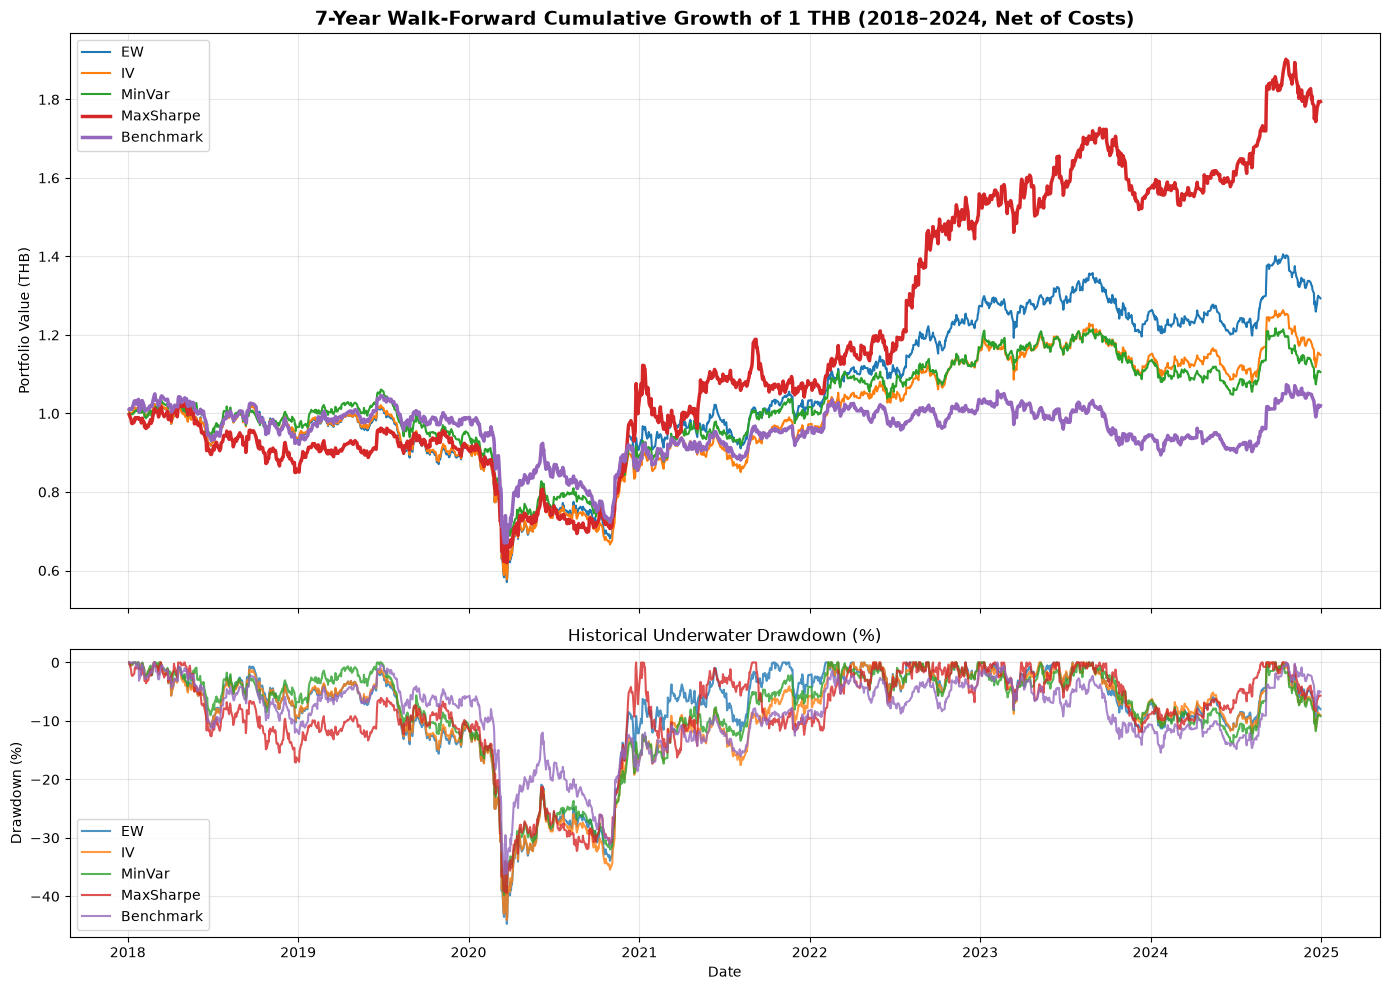

In [10]:
# 1. คำนวณ Wealth Index และ Drawdown
cum_returns = (1 + backtest_returns).cumprod()
drawdowns = calculate_drawdowns(backtest_returns) * 100

# 2. วาดกราฟ 2 หน้าต่าง (แผงบน: มูลค่าพอร์ต, แผงล่าง: Underwater Drawdown)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

# แผงบน: เส้นการเติบโตสะสมของเงิน 1 บาท (Equity Curve)
for col in cum_returns.columns:
    lw = 2.5 if col in ["MaxSharpe", "Benchmark"] else 1.5
    ax1.plot(cum_returns.index, cum_returns[col], label=col, linewidth=lw)
ax1.set_title("7-Year Walk-Forward Cumulative Growth of 1 THB (2018–2024, Net of Costs)", fontsize=14, fontweight="bold")
ax1.set_ylabel("Portfolio Value (THB)")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper left")

# แผงล่าง: กราฟ Underwater Drawdown (%)
for col in drawdowns.columns:
    ax2.plot(drawdowns.index, drawdowns[col], label=col, alpha=0.8)
ax2.set_title("Historical Underwater Drawdown (%)", fontsize=12)
ax2.set_ylabel("Drawdown (%)")
ax2.set_xlabel("Date")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()

### Notes: บทวิเคราะห์ผลลัพธ์สำคัญ (Quant Performance Insights)

1. **ตลาดหุ้นไทย (Benchmark TDEX / SET50) ตลอด 7 ปี (2018–2024) อยู่ในภาวะซบเซา (Sideways-down)**:
   - ผลตอบแทนทบต้นของ Benchmark อยู่ที่เพียง **+1.49% ต่อปี** (ต่ำกว่าดอกเบี้ยเงินฝากหรือตั๋วเงินคลัง 2.5%)
   - ส่งผลให้ **Sharpe Ratio ของตลาดติดลบ (-0.07)**

2. **ทุกกลยุทธ์จัดพอร์ตเชิงปริมาณสร้าง Alpha ชนะ Benchmark ได้ทั้งหมด**:
   - **Equal-Weight (EW)**: ได้ผลตอบแทน **+5.44% ต่อปี** ด้วย **Turnover ต่ำมากเพียง 7.14%** (แทบไม่เสียค่าคอมมิชชั่นเลย)
   - **Minimum-Variance (Min-Var)**: มีความผันผวนเพียง **15.25% ต่อปี** ซึ่งต่ำกว่า Benchmark ตอกย้ำพลังของการกระจายความเสี่ยงข้ามอุตสาหกรรม
   - **Maximum-Sharpe (Max-Sharpe)**: โดดเด่นที่สุดในแง่ผลตอบแทน **+10.75% ต่อปี** และ **Sharpe Ratio สูงถึง 0.42** ถึงแม้จะมี Turnover สูง (126.95% ต่อปี) แต่ผลตอบแทนส่วนเพิ่ม (Excess Return) ก็สูงเกินพอที่จะชดเชยต้นทุนค่าธรรมเนียมได้สบายๆ